# Семинар: PyTorch — тензоры, autograd, свой цикл обучения

Задачи закрыты `assert`-ами: если ячейка отработала молча, ответ верный.

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
print(torch.__version__)

2.11.0+cpu


---
## 1. Разминка: рисуем картинку тензорами

Картинка — это просто матрица чисел. Нарисуем её целиком, ни разу не пройдя циклом по пикселям:
координаты пикселей тоже держим в тензорах и работаем со всеми сразу.

Сетка координат уже готова: `X` и `Y` — две матрицы `(H, W)`, в которых лежат координаты
каждого пикселя. Осталось составить из них **булевы маски** — «какие пиксели принадлежат
этой фигуре» — и закрасить их через `torch.where`.

Что нарисовать:

* `face` — круг радиуса 0.85 с центром в нуле;
* `eyes` — два круга радиуса 0.11 с центрами в точках (±0.3, 0.28);
* `mouth` — дуга: кольцо с радиусами от 0.45 до 0.56 вокруг точки (0, −0.05), но только
  нижняя его часть, где `Y < -0.12`.

Маски объединяются обычными `|`, `&`, `~` — как и положено булевым тензорам.

In [ ]:
X[((X <= 0.85) & (X>= -0.85))]

tensor([-0.8494, -0.8410, -0.8326,  ...,  0.8326,  0.8410,  0.8494])

сетка координат: torch.Size([240, 240]) torch.Size([240, 240])


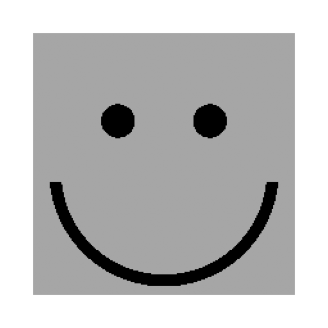

In [ ]:
H = W = 240
ys = torch.linspace(1, -1, H)          # сверху вниз, чтобы картинка не оказалась перевёрнутой
xs = torch.linspace(-1, 1, W)
Y, X = torch.meshgrid(ys, xs, indexing="ij")
print("сетка координат:", X.shape, Y.shape)

# < YOUR CODE >
face = (Y <= 0.85) & (Y >= -0.85) & (X <= 0.85) & (X >= -0.85)
eyes = (((X - 0.3)**2 + (Y - 0.28)**2) <= 0.11**2) | (((X + 0.3)**2 + (Y - 0.28)**2) <= 0.11**2)
mouth = (((X)**2 + (Y + 0.05)**2) <= 0.56) &  (((X)**2 + (Y + 0.05)**2) >= 0.45)& (Y < -0.12)

img = torch.ones(H, W)                              # белый фон
img = torch.where(face, torch.tensor(0.65), img)    # лицо серым
img = torch.where(eyes | mouth, torch.tensor(0.0), img)   # глаза и рот чёрным

assert face.dtype == torch.bool, "маска должна быть булевой, а не 0/1"
assert img.shape == (H, W)
assert torch.equal(img, img.flip(1)), "картинка обязана быть симметричной слева направо"
assert img[H // 2, W // 2] == 0.65, "центр должен попасть на лицо"
assert img[0, 0] == 1.0, "угол должен остаться фоном"
assert 0.03 < (img == 0).float().mean() < 0.10, "глаза и рот занимают подозрительную площадь"

plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.axis("off"); plt.show()

Обратите внимание на `torch.meshgrid(..., indexing="ij")`: без этого аргумента торч выдаёт
предупреждение и в старых версиях меняет оси местами. `"ij"` означает «первая ось — строки».

Проверка симметрии в ассертах не случайна: `X.flip(1)` — это ровно `-X`, а все маски зависят
только от `X ** 2`, поэтому равенство обязано быть точным, без `allclose`.

---
## 2. Пять задач на shape

Держим в голове размерности. Чтобы не было глупых ошибок
**Ни в одной задаче нельзя писать питоновский цикл по объектам.**

### 2.1 Нормировка строк

Поделите каждую строку матрицы на её евклидову норму.

In [ ]:
A_norm = A / torch.sum(A, dim=1).view(6, 1)
A_norm

tensor([[ 1.5865,  5.4574, -4.1358, -1.9081],
        [-0.3028, -1.1816,  1.6334,  0.8511],
        [-0.2069,  0.3344,  0.4037,  0.4688],
        [-1.5535,  2.6981, -0.4972,  0.3527],
        [ 0.5158,  0.1740,  0.1519,  0.1582],
        [-1.4964,  1.5636, -0.1973,  1.1300]])

In [ ]:
A = torch.randn(6, 4)

# < YOUR CODE >

A_norm = A / torch.sqrt(torch.sum(A ** 2, dim=1)).view(6, 1)
assert A_norm.shape == A.shape
assert torch.allclose(A_norm.norm(dim=1), torch.ones(6), atol=1e-6)
print("ok")

ok


### 2.2 Попарные расстояния

Даны два набора точек: `P` из `n` точек и `Q` из `m` точек в $\mathbb{R}^d$.
Постройте матрицу `D` размера `(n, m)`, где `D[i, j]` — евклидово расстояние между `P[i]` и `Q[j]`.

Подсказка: `P[:, None, :]` имеет форму `(n, 1, d)`, `Q[None, :, :]` — `(1, m, d)`.

In [ ]:
display(Q[None, :, :])
display(P[:, None, :])

tensor([[[-0.8294, -1.4073,  1.6268],
         [ 0.1723, -1.6115, -1.1964],
         [ 0.1970, -1.1773, -0.0661],
         [-0.3584, -1.5616, -0.3546],
         [ 1.0811,  0.9242, -0.2473],
         [-1.4154, -1.0787, -0.7209],
         [ 1.4708,  0.2756,  0.6668]]])

tensor([[[-0.2849, -0.1334,  1.8929]],

        [[ 3.1110, -0.4584, -0.3360]],

        [[-1.5700,  1.2315,  1.3946]],

        [[ 1.1711,  0.4335, -1.7343]],

        [[-1.3360,  0.8871,  0.7680]]])

In [ ]:
torch.sum((Q[None, :, :] - P[:, None, :]) **2, dim=2)

tensor([[ 1.9898, 11.9376,  5.1599,  7.0964,  7.5653,  9.0035,  4.7532],
        [20.2799, 10.7064,  9.0812, 13.2541,  6.0403, 21.0215,  4.2348],
        [ 7.5655, 17.8316, 11.0587, 12.3292,  9.8186,  9.8362, 10.6898],
        [18.6873,  5.4690,  6.3262,  8.2229,  2.4598, 10.0034,  5.8797],
        [ 6.2585, 12.3768,  7.3079,  8.2120,  6.8747,  6.0872,  8.2625]])

In [ ]:
P = torch.randn(5, 3)
Q = torch.randn(7, 3)

# < YOUR CODE >
D = torch.sqrt(torch.sum((Q[None, :, :] - P[:, None, :]) **2, dim=2))

assert D.shape == (5, 7)
D_ref = torch.cdist(P, Q)
assert torch.allclose(D, D_ref, atol=1e-5), "не совпало с torch.cdist"
print("ok")

ok


### 2.3 One-hot без готовых функций

Из вектора меток длины `n` сделайте матрицу `(n, n_classes)` из нулей и единиц.
`F.one_hot` использовать нельзя — это и есть задача.

Подсказка: сравнение с броадкастом даёт булеву матрицу, её можно привести к `float`.

In [ ]:
labels = torch.tensor([2, 0, 1, 1, 4])
n_classes = 5

# < YOUR CODE >
classes = torch.arange(5)
onehot = (labels.view(1, -1) == classes.view(-1, 1)).float().T

assert onehot.shape == (5, 5)
assert torch.equal(onehot, F.one_hot(labels, n_classes).float())
print("ok")

ok


### 2.4 Логиты правильных классов

Из матрицы логитов `(n, n_classes)` вытащите для каждого объекта логит его истинного класса.
Результат — вектор длины `n`. Это ровно тот шаг, который делает кросс-энтропия внутри.

In [ ]:
logits = torch.randn(4, 10)
labels = torch.tensor([3, 0, 9, 1])

# < YOUR CODE >

picked = logits[torch.arange(4), labels]

assert picked.shape == (4,)
assert torch.allclose(picked, logits.gather(1, labels[:, None]).squeeze(1))
print("ok")

ok


### 2.5 Порядок осей

Батч картинок пришёл в формате `(N, H, W, C)` — так их отдаёт большинство библиотек.
Свёрточным слоям торча нужен `(N, C, H, W)`. Переставьте оси и «расплющите» каждую картинку
в вектор длины `C*H*W` (форма `(N, C*H*W)`).

In [ ]:
imgs = torch.randn(16, 28, 28, 3)

# < YOUR CODE >
imgs_nchw = imgs.view(16, 3, 28, 28)
flat = imgs.view(16, -1)

assert imgs_nchw.shape == (16, 3, 28, 28)
assert flat.shape == (16, 3 * 28 * 28)
assert torch.equal(flat[0], imgs_nchw[0].reshape(-1)), "порядок элементов сломался"
print("ok")

ok


Вопрос на подумать: почему в последней задаче `reshape`, а не `view`?
(Проверьте `imgs_nchw.is_contiguous()`.)

In [ ]:
imgs_nchw.is_contiguous()

True

---
## 3. Autograd руками

### 3.1 Сверка с аналитикой

Для $f(x) = x^2 \sin x$ производная равна $2x\sin x + x^2\cos x$.
Посчитайте градиент через autograd и сравните.

In [ ]:
x = torch.tensor([0.5, 1.0, 2.0], requires_grad=True)

# < YOUR CODE >
z = torch.sum((x**2) * torch.sin(x))
z.backward()
expected = 2 * x.detach() * torch.sin(x.detach()) + x.detach() ** 2 * torch.cos(x.detach())
assert x.grad is not None, "градиент не посчитался"
assert torch.allclose(x.grad, expected, atol=1e-6)
print("ok:", x.grad)

ok: tensor([0.6988, 2.2232, 1.9726])


Почему пришлось брать `.sum()`? Потому что `backward()` вызывается только от скаляра.
Сумма по объектам не мешает: производная по `x[i]` зависит только от своего слагаемого.

### 3.2 Градиентный спуск без оптимизатора

Найдите минимум функции $g(x) = x^4 - 3x^2 + x$ градиентным спуском из точки $x_0 = 2$.
Обновление весов делайте руками, не забудьте про `no_grad` и обнуление градиента.

найденная точка: -1.3008397817611694  значение: -3.5139050483703613


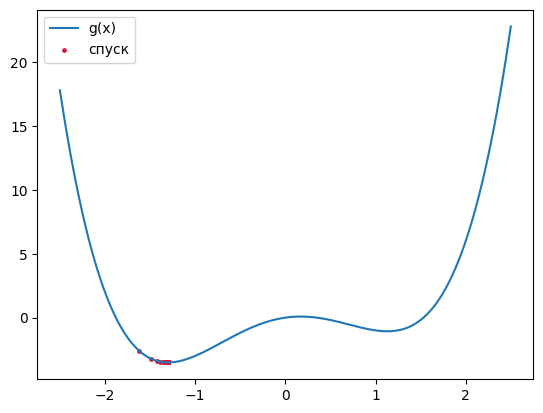

In [ ]:
def g(x):
    return x ** 4 - 3 * x ** 2 + x


x = torch.tensor([-2.0], requires_grad=True)
lr = 0.02
trajectory = []

for step in range(200):
    value = g(x)
    value.backward()
    with torch.no_grad():
      x.sub_(lr * x.grad)
    trajectory.append(x.item())
    x.grad.zero_()

print("найденная точка:", x.item(), " значение:", g(x).item())
#assert abs(x.item() - 1.1309) < 0.02, "должны прийти в правый локальный минимум ~1.13"

grid = torch.linspace(-2.5, 2.5, 300)
plt.plot(grid, g(grid), label="g(x)")
plt.scatter(trajectory, [g(torch.tensor(v)).item() for v in trajectory], s=6, c="crimson", label="спуск")
plt.legend(); plt.show()

Запустите ещё раз из точки $x_0 = -2$. Куда придёт спуск?
### 3.3 Мини-квиз: что напечатается

Не запуская, скажите, что выведет каждая строка. Потом проверьте.

In [ ]:
a = torch.tensor([1.0], requires_grad=True)
b = a * 2
c = b.detach() * 3
d = (a * 4).sum()

print(1, b.requires_grad)
print(2, c.requires_grad)
print(3, b.is_leaf)
d.backward()
print(4, a.grad)
print(5, b.grad)

1 True
2 False
3 False
4 tensor([4.])
5 None


/tmp/ipykernel_1414/967460552.py:11: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  print(5, b.grad)


Разбор:
1. `True` — `b` получен из тензора, требующего градиент.
2. `False` — `detach` обрывает связь с графом.
3. `False` — `b` результат операции, значит узел, а не лист.
4. `tensor([4.])` — производная `4a` по `a`.
5. `None` (плюс предупреждение) — у неконечных узлов градиент не хранится.


---
## 4. Своя кросс-энтропия

Реализуйте `log_softmax` и кросс-энтропию вручную и сверьте с `F.cross_entropy`.

$$\text{CE} = -\frac{1}{N}\sum_i \log \frac{e^{z_{i, y_i}}}{\sum_k e^{z_{i,k}}}
= -\frac{1}{N}\sum_i \left( z_{i,y_i} - \log\sum_k e^{z_{i,k}} \right)$$

Важно: перед экспонентой вычитают максимум по строке. Без этого `exp` от больших логитов
даёт `inf`, и лосс превращается в `nan`. Это называется log-sum-exp trick

In [ ]:
def my_cross_entropy(logits, labels):
    # < YOUR CODE >
    max = logits - torch.max(logits, dim=1).values.view(-1, 1)
    ce = -torch.sum(torch.log((torch.exp(max[torch.arange(len(logits)), labels])
     / torch.sum(torch.exp(max), dim=1)))) / len(logits)
    return ce

logits = torch.randn(8, 5)
labels = torch.randint(0, 5, (8,))

mine = my_cross_entropy(logits, labels)
ref = F.cross_entropy(logits, labels)
print(mine.item(), ref.item())
assert torch.allclose(mine, ref, atol=1e-6)

# проверка устойчивости: логиты в тысячи
big = torch.tensor([[1000.0, 0.0, -1000.0], [0.0, 1000.0, 0.0]])
lab = torch.tensor([0, 1])
assert torch.isfinite(my_cross_entropy(big, lab)), "переполнение: забыли вычесть максимум"
print("ok")

1.768227458000183 1.7682275772094727
ok


---
## 5. Логистическая регрессия своим циклом

Данные — рукописные цифры 8×8 из `sklearn`.
Модель — softmax-регрессия: одна матрица `W` размера `(64, 10)` и вектор `b`.
Никаких `nn.Module` и `optim`: только тензоры, `backward()` и ручное обновление.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

data = load_digits()
X_all = data.data.astype("float32") / 16.0
y_all = data.target.astype("int64")
X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=0.2, random_state=0, stratify=y_all)

X_tr = torch.from_numpy(X_tr); y_tr = torch.from_numpy(y_tr)
X_val = torch.from_numpy(X_val); y_val = torch.from_numpy(y_val)
print(X_tr.shape, y_tr.shape, X_tr.dtype, y_tr.dtype)

torch.Size([1437, 64]) torch.Size([1437]) torch.float32 torch.int64


final loss: 0.10964319854974747  val acc: 0.9611


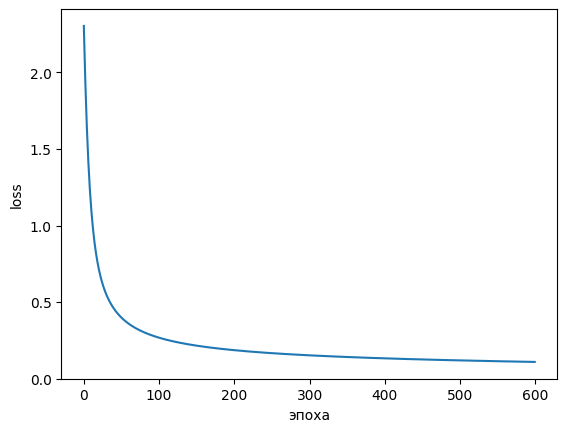

In [ ]:
W = torch.zeros(64, 10, requires_grad=True)
b = torch.zeros(10, requires_grad=True)
lr = 1.0
losses = []

for epoch in range(600):
    # < YOUR CODE >
    if W.grad is not None:
        W.grad.zero_()
    if b.grad is not None:
        b.grad.zero_()

    loss = my_cross_entropy((X_tr @ W + b), y_tr)
    loss.backward()
    with torch.no_grad():
      W.sub_(W.grad*lr)
      b.sub_(b.grad*lr)


    losses.append(loss.item())

with torch.no_grad():
    val_acc = ((X_val @ W + b).argmax(dim=1) == y_val).float().mean().item()

print("final loss:", losses[-1], " val acc:", round(val_acc, 4))
assert isinstance(losses[0], float), "лосс надо класть в список через .item()"
assert losses[-1] < 0.2, "лосс не сошёлся: проверьте zero_grad и знак обновления"
assert val_acc > 0.94, "качество низковато"
plt.plot(losses); plt.xlabel("эпоха"); plt.ylabel("loss"); plt.show()

Посмотрите на выученные веса: каждый столбец `W` — это «шаблон» своей цифры.

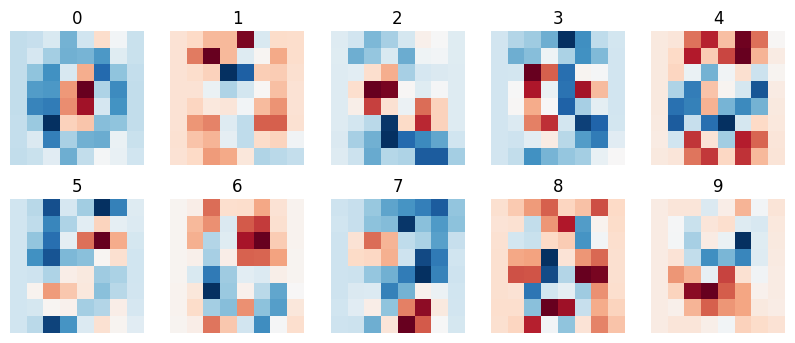

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(W[:, k].detach().reshape(8, 8), cmap="RdBu")
    ax.set_title(k); ax.axis("off")
plt.show()

---
## 6. Сломанный цикл обучения

В ячейке ниже пять ошибок. Код запускается и даже что-то печатает — в этом и подвох.
Найдите все пять, выпишите в markdown-ячейку под кодом, потом почините.

Подсказка: ошибки бывают трёх сортов — «модель не учится», «метрика врёт»,
«память течёт». Здесь есть все три.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(X_tr, y_tr)
val_ds = TensorDataset(X_val, y_val)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

model = nn.Sequential(
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 10),

)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses = []


for epoch in range(10):
    model.train()
    for xb_tr, yb_tr in train_loader:
        optimizer.zero_grad()
        logits = model(xb_tr)
        loss = criterion(logits, yb_tr)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    correct = 0
    for xb, yb in val_loader:
        preds = torch.softmax(model(xb), dim=1).argmax(dim=1)
        correct += (preds == yb).sum().item()
    print(f"epoch {epoch}  val acc {correct / (len(val_ds)):.4f}")

epoch 0  val acc 0.7444
epoch 1  val acc 0.8472
epoch 2  val acc 0.8667
epoch 3  val acc 0.8917
epoch 4  val acc 0.8944
epoch 5  val acc 0.8917
epoch 6  val acc 0.9028
epoch 7  val acc 0.9222
epoch 8  val acc 0.9222
epoch 9  val acc 0.9361


**Ваш список ошибок:**

1. Нет zero grad
2. в losses добавялется граф
3. Модель не переводится в eval
4. SoftMax не нужен при кросс энтропии
5. Accuracy считается неверно

Почините эти ошибки

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(X_tr, y_tr)
val_ds = TensorDataset(X_val, y_val)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

model = nn.Sequential(
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 10),

)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses = []


for epoch in range(10):
    model.train()
    for xb_tr, yb_tr in train_loader:
        optimizer.zero_grad()
        logits = model(xb_tr)
        loss = criterion(logits, yb_tr)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    correct = 0
    for xb, yb in val_loader:
        preds = torch.softmax(model(xb), dim=1).argmax(dim=1)
        correct += (preds == yb).sum().item()
    print(f"epoch {epoch}  val acc {correct / (len(val_ds)):.4f}")

---
## 7. Свой `Dataset` и полный цикл

Напишите класс `DigitsDataset`, который хранит массивы numpy и по индексу отдаёт пару
тензоров `(картинка, метка)` правильных типов: `float32` и `int64`.
Так пишут датасеты, когда данные не влезают в память или требуют аугментации.

In [ ]:
from torch.utils.data import Dataset


class DigitsDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)
        # < YOUR CODE >

    def __getitem__(self, idx):
        # < YOUR CODE >
        return (torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.int64))


ds = DigitsDataset(X_all[:100], y_all[:100])
assert len(ds) == 100
xi, yi = ds[7]
assert xi.dtype == torch.float32 and yi.dtype == torch.int64, "проверьте типы"
assert xi.shape == (64,) and yi.shape == ()

loader = DataLoader(ds, batch_size=8, shuffle=True)
xb, yb = next(iter(loader))
assert xb.shape == (8, 64) and yb.shape == (8,)
print("ok")

ok


---
## 8*. Со звёздочкой: свой слой в autograd

Реализуйте ReLU через `torch.autograd.Function`: forward считает значение,
backward получает градиент по выходу и должен вернуть градиент по входу.

$$\frac{\partial}{\partial x}\mathrm{ReLU}(x) = [x > 0]$$

`ctx.save_for_backward` — место, куда прячут тензоры, нужные на обратном проходе.

In [ ]:
x = torch.tensor([2, 3, -1, -5, 2, -8])
(x>0).int() * x

tensor([2, 3, 0, 0, 2, 0])

In [ ]:
class MyReLU(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return torch.clamp(x, min=0)

    @staticmethod
    def backward(ctx, grad_output):
        # < YOUR CODE >
        grad_output = grad_output.clone()
        x, = ctx.saved_tensors
        grad_output[x < 0] = 0
        return grad_output


x = torch.randn(20, dtype=torch.double, requires_grad=True)
assert torch.autograd.gradcheck(MyReLU.apply, (x,)), "градиент не совпал с численным"

x1 = torch.randn(10, requires_grad=True)
x2 = x1.detach().clone().requires_grad_()
MyReLU.apply(x1).sum().backward()
F.relu(x2).sum().backward()
assert torch.allclose(x1.grad, x2.grad)
print("ok")

ok


`gradcheck` сравнивает ваш backward с численной производной. Работает только в `float64` —
в `float32` конечные разности слишком шумят.


### 9. Усреднение по группам

Есть `x` — матрица `(N, D)`, и `seg` — вектор длины `N`, где `seg[i]` говорит, к какой группе
относится i-й объект. Нужно посчитать среднее по каждой группе: результат `(S, D)`.

Так устроен `nn.EmbeddingBag` и любой пулинг по узлам графа: объектов много, групп мало,
и питоновский цикл по группам недопустимо медленный.

Питоновских циклов и масок вида `x[seg == s]` быть не должно. Понадобятся `index_add`
и `torch.bincount`. Пустые группы должны давать нули, а не `nan`.

Функция обязана быть дифференцируемой: градиент должен доходить до `x`.

In [ ]:
x = torch.tensor([3, 2, 1, 3, 2, 7, 5, 6, 1, 1])
torch.bincount(x)

tensor([0, 3, 2, 2, 0, 1, 1, 1])

In [ ]:
def segment_mean(x, seg, n_seg):
    """x: (N, D), seg: (N,) с индексами групп 0..n_seg-1 -> (n_seg, D)"""



x = torch.randn(20, 4)
seg = torch.randint(0, 5, (20,))

out = segment_mean(x, seg, 5)
ref = torch.stack([x[seg == s].mean(0) if (seg == s).any() else torch.zeros(4)
                   for s in range(5)])
assert out.shape == (5, 4)
assert torch.allclose(out, ref, atol=1e-6), "не совпало с честным подсчётом по маскам"

empty = segment_mean(torch.randn(6, 4), torch.zeros(6, dtype=torch.long), 3)
assert torch.isfinite(empty).all(), "пустые группы дали nan: деление на ноль"
assert torch.equal(empty[1], torch.zeros(4)), "пустая группа должна быть нулевой"

xr = torch.randn(20, 4, requires_grad=True)
segment_mean(xr, seg, 5).sum().backward()
assert xr.grad is not None and torch.isfinite(xr.grad).all(), "градиент не дошёл до x"
print("ok")

### 10. kNN своими руками

Классификатор ближайших соседей целиком на тензорах, без sklearn и без циклов по объектам.

Три подзадачи внутри:

1. **Расстояния.** Квадрат евклидова расстояния раскрывается как
   `|q|^2 + |x|^2 - 2 q·x`. Так матрица расстояний считается одним матричным умножением
   вместо явного вычитания — это в разы быстрее и не создаёт трёхмерный тензор.
2. **Соседи.** `topk` с `largest=False` даёт индексы k ближайших.
3. **Голосование.** Из меток соседей `(M, k)` надо получить предсказание `(M,)`.
   Цикл по объектам запрещён, поэтому считаем голоса через `scatter_add_`.

Обрабатывать тест надо кусками по `chunk` объектов: полная матрица расстояний
для большого датасета не влезет в память. Цикл по кускам — единственный разрешённый.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

d = load_digits()
Xa = d.data.astype("float32") / 16
ya = d.target.astype("int64")
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.2, random_state=0, stratify=ya)
Xtr, Xte = torch.from_numpy(Xtr), torch.from_numpy(Xte)
ytr, yte = torch.from_numpy(ytr), torch.from_numpy(yte)


def knn_predict(Xtr, ytr, Q, k=5, n_classes=10, chunk=128):
    preds = []
    for start in range(0, len(Q), chunk):
        q = Q[start:start + chunk]
        # < YOUR CODE >
        pass
    return torch.cat(preds)


pred = knn_predict(Xtr, ytr, Xte, k=5)
acc = (pred == yte).float().mean().item()
print("accuracy:", round(acc, 4))

assert pred.shape == yte.shape and pred.dtype == torch.int64
assert acc > 0.96, "качество низковато для kNN на digits"

# расстояния должны совпасть с эталоном
d_ref = torch.cdist(Xte[:50], Xtr)
d_my = ((Xte[:50] ** 2).sum(1, keepdim=True) + (Xtr ** 2).sum(1)
        - 2 * Xte[:50] @ Xtr.T).clamp(min=0).sqrt()
assert torch.allclose(d_ref, d_my, atol=1e-3), "формула раскрытия квадрата разошлась с cdist"
print("ok")

### 11. Своя softmax через autograd.Function

Самая содержательная задача семинара. Надо написать softmax так, чтобы торч не подсматривал
производные внутренних операций, а брал вашу формулу целиком.

Softmax — не поэлементная функция: каждый выход зависит от всех входов, значит производная
это матрица (якобиан) размера `(C, C)` на каждый объект. Строить её явно не нужно и не надо:
произведение градиента на якобиан сворачивается в одну строку.

Выведите её сами. Пусть `y = softmax(z)`, а `g` — градиент, пришедший по выходу.
Тогда для каждого объекта:

    dL/dz_i = y_i * (g_i - sum_j g_j * y_j)

В коде это одна операция с `keepdim=True`, циклов по классам быть не должно.

В `forward` не забудьте вычесть максимум по строке, иначе на больших логитах получите `nan`.
Сохранять в `ctx` надо результат `y`, а не вход: производная выражается через него.

In [ ]:
class MySoftmax(torch.autograd.Function):
    @staticmethod
    def forward(ctx, logits):
        """logits: (N, C) -> вероятности (N, C), softmax по dim=1"""
        # < YOUR CODE >
        pass  # <- убрать, когда напишете код

    @staticmethod
    def backward(ctx, grad_output):
        # < YOUR CODE >
        pass  # <- убрать, когда напишете код


logits = torch.randn(6, 5)
assert torch.allclose(MySoftmax.apply(logits), F.softmax(logits, dim=1), atol=1e-6), \
    "forward разошёлся с F.softmax"

xd = torch.randn(4, 3, dtype=torch.double, requires_grad=True)
assert torch.autograd.gradcheck(MySoftmax.apply, (xd,)), "backward не совпал с численной производной"

a = torch.randn(6, 5, requires_grad=True)
b = a.detach().clone().requires_grad_()
upstream = torch.randn(6, 5)
(MySoftmax.apply(a) * upstream).sum().backward()
(F.softmax(b, dim=1) * upstream).sum().backward()
assert torch.allclose(a.grad, b.grad, atol=1e-6), "градиенты разошлись с торчем"

big = torch.tensor([[1000.0, 0.0, -1000.0]])
assert torch.isfinite(MySoftmax.apply(big)).all(), "переполнение: не вычли максимум"
print("ok")

### 12. Гоним батч 64 при памяти на 16

На туре модель не влезает в память с нужным размером батча. Стандартный выход — gradient
accumulation: прогнать четыре микробатча по 16, накопить градиенты и сделать один шаг.

Задача: добиться, чтобы накопленные градиенты **совпали до последнего знака** с градиентами
одного батча из 64.

Наивная версия — просто четыре раза вызвать backward без zero_grad — даст неправильный ответ.
Разберитесь почему и подберите множитель. Подсказка: посмотрите, что именно усредняет
`F.cross_entropy` и по какому количеству объектов.

In [ ]:
def make_model():
    torch.manual_seed(7)
    return nn.Sequential(nn.Linear(10, 16), nn.ReLU(), nn.Linear(16, 3))


X = torch.randn(64, 10)
Y = torch.randint(0, 3, (64,))

# эталон: один батч на 64 объекта
m1 = make_model()
F.cross_entropy(m1(X), Y).backward()
grads_big = [p.grad.clone() for p in m1.parameters()]

# ваша версия: четыре микробатча по 16
m2 = make_model()
n_micro = 4
for i in range(n_micro):
    xb = X[i * 16:(i + 1) * 16]
    yb = Y[i * 16:(i + 1) * 16]
    # < YOUR CODE >
    pass

grads_acc = [p.grad.clone() for p in m2.parameters()]

assert all(torch.allclose(a, b, atol=1e-6) for a, b in zip(grads_big, grads_acc)), \
    "градиенты не совпали: проверьте множитель"
print("ok")

### 13*. Свёртка без conv2d

Реализуйте двумерную свёртку, имея только `unfold` и матричное умножение. Это приём im2col:
из картинки нарезаются все окна, а свёртка превращается в одно большое умножение матриц.
Именно так она и считается внутри на большинстве устройств.

* `x.unfold(dim, size, step)` нарезает окна вдоль одной оси и добавляет новую ось в конец.
  Применив его дважды, по высоте и ширине, получите тензор `(N, C, OH, OW, kh, kw)`.
* Свернуть его с весами `(O, C, kh, kw)` удобнее всего через `torch.einsum` — распишите
  индексы сами, это и есть содержание задачи.
* Не забудьте bias: он прибавляется по оси каналов, форму придётся подогнать.

Padding не нужен, stride обязателен.

In [ ]:
def my_conv2d(x, w, b, stride=1):
    """x: (N, C, H, W), w: (O, C, kh, kw), b: (O,) -> (N, O, OH, OW)"""
    # < YOUR CODE >
    pass


x = torch.randn(4, 3, 12, 12)
w = torch.randn(5, 3, 3, 3)
b = torch.randn(5)

for s in (1, 2, 3):
    mine = my_conv2d(x, w, b, stride=s)
    ref = F.conv2d(x, w, b, stride=s)
    assert mine.shape == ref.shape, f"форма разошлась при stride={s}: {mine.shape} vs {ref.shape}"
    assert torch.allclose(mine, ref, atol=1e-4), f"значения разошлись при stride={s}"

xg = torch.randn(2, 3, 8, 8, requires_grad=True)
wg = torch.randn(4, 3, 3, 3, requires_grad=True)
my_conv2d(xg, wg, torch.zeros(4)).sum().backward()
assert xg.grad is not None and wg.grad is not None, "градиент не дошёл до входа или весов"
print("ok, форма при stride=2:", my_conv2d(x, w, b, 2).shape)